<div align="center" style="font-family: 'Times New Roman', serif;">
    <h3>In The Name of God</h3>
    <img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="Sharif University Logo" width="140" height="140">
    <h4>Sharif University of Technology - Department of Electrical Engineering</h4>
    <h2 style="color: #008080;">Communication Systems</h2>
    <hr/>
    <h3 style="color: #800080;">Computer Assignment 1: Fundamentals of Signals, Channels, and Spectral Analysis</h3>
    <h4>Instructor: Dr. Pakravan</h4>
    <h4>Fall 2026</h4>
    <hr/>
    <div style="text-align: left; display: inline-block; max-width: 750px;">
        <p><b>Submission Guidelines:</b></p>
        <ul>
            <li>Complete all code blocks marked with <code>...</code> or <code># TODO</code>.</li>
            <li>All plots must include clear titles, axis labels (with appropriate units), and legends.</li>
            <li>Provide rigorous mathematical and physical explanations in the designated <b>Answer</b> Markdown cells.</li>
            <li>Submit your executed Jupyter Notebook (<code>.ipynb</code>) along with a PDF export and generated audio files in a single archive named <code>CA01_StudentID_FullName.zip</code>.</li>
        </ul>
    </div>
    <hr/>
</div>

In [22]:
# Please enter your information below
Name = "Aria Fateh Kerdari"
Student_ID = "403110382"

# Import Libraries
Run the following cell to import the required Python libraries. You may import additional standard functions from `scipy` or `numpy` if needed.

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.fft import fft, ifft, fftshift, fftfreq
import soundfile as sf
import librosa
import os
from sklearn.metrics import mean_squared_error

# Configure default plot style
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True

---
# Question 1: Fourier Transform Properties, Rayleigh's Energy Theorem, and Bandwidth Metrics (25 Points)

Understanding the interplay between the time-domain duration of a pulse and its frequency-domain spectral extent is the foundation of communication systems engineering. In this question, you will numerically verify key properties of the Continuous-Time Fourier Transform (CTFT)—specifically **Hermitian Symmetry**, **Time Scaling**, **Integration**, **Rayleigh's Energy Theorem**, and **Bandwidth Definitions** ($3\text{-dB}$, **Null-to-Null**, and **RMS Bandwidth**).

### 1.1. Rectangular vs. Triangular Pulses via Time-Domain Integration
Consider the antisymmetric double-rectangular pulse $g_1(t)$ defined over $t \in [-0.5, 0.5]\text{ s}$:
$$g_1(t) = A \left[ \text{rect}\left(\frac{t + T/2}{T}\right) - \text{rect}\left(\frac{t - T/2}{T}\right) \right]$$
As derived in the lecture notes, integrating $g_1(t)$ over time yields the symmetric triangular pulse $g_2(t)$:
$$g_2(t) = \int_{-\infty}^{t} g_1(\tau)\,d\tau = A T \, \Lambda\left(\frac{t}{T}\right) \quad \Longleftrightarrow \quad G_2(f) = \frac{1}{j2\pi f} G_1(f) = A T^2 \, \text{sinc}^2(f T)$$

1. Set $f_s = 10\text{ kHz}$, time window $t \in [-0.5, 0.5]\text{ s}$, amplitude $A = 1$, and pulse width parameter $T = 0.02\text{ s}$ ($20\text{ ms}$).
2. Construct $g_1(t)$ in Python and compute $g_2(t)$ numerically using cumulative integration (`np.cumsum(g1) / fs`).
3. Compute the continuous-time Fourier Transform approximation $G_1(f)$ and $G_2(f)$ using `fftshift(fft(...)) / fs`. Plot $|G_1(f)|$ and $|G_2(f)|$ alongside the theoretical curve $|G_{2,\text{theory}}(f)| = A T^2 \text{sinc}^2(fT)$ over $f \in [-250, 250]\text{ Hz}$.
4. Verify **Hermitian Symmetry** for the real signal $g_2(t)$ by plotting its magnitude $|G_2(f)|$ (even symmetry) and unwrapped phase $\angle G_2(f)$ (odd symmetry).

(-250.0, 250.0)

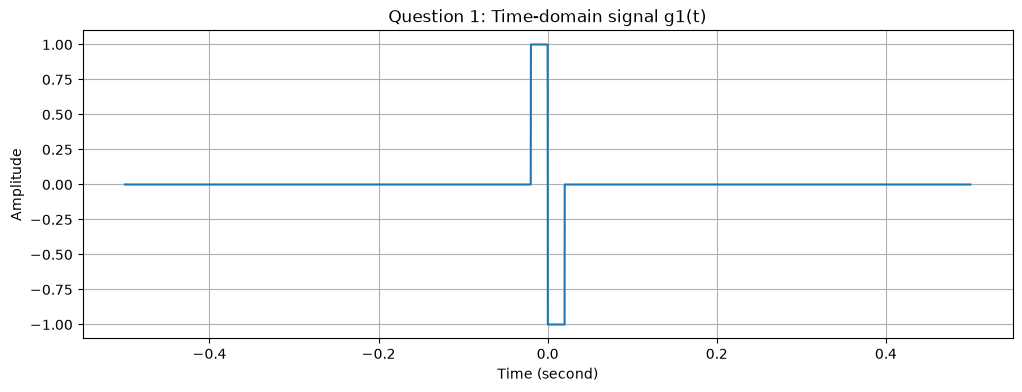

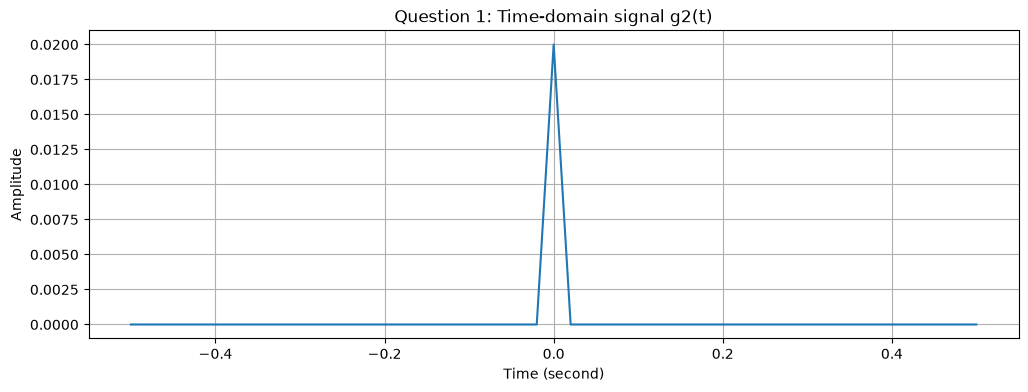

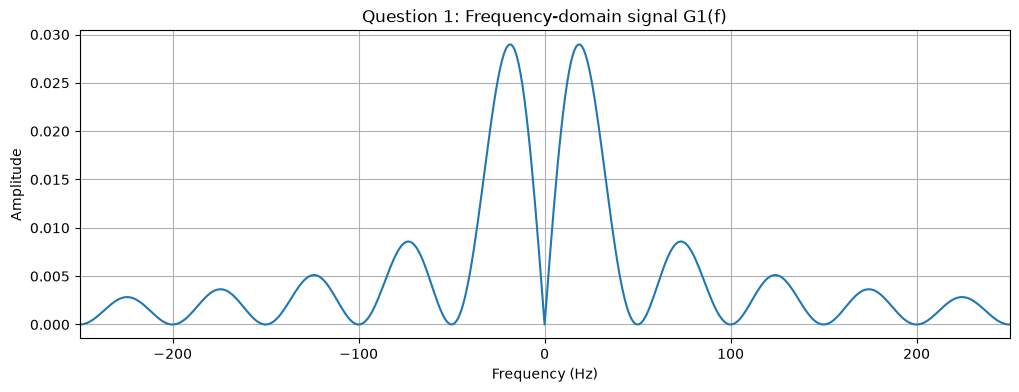

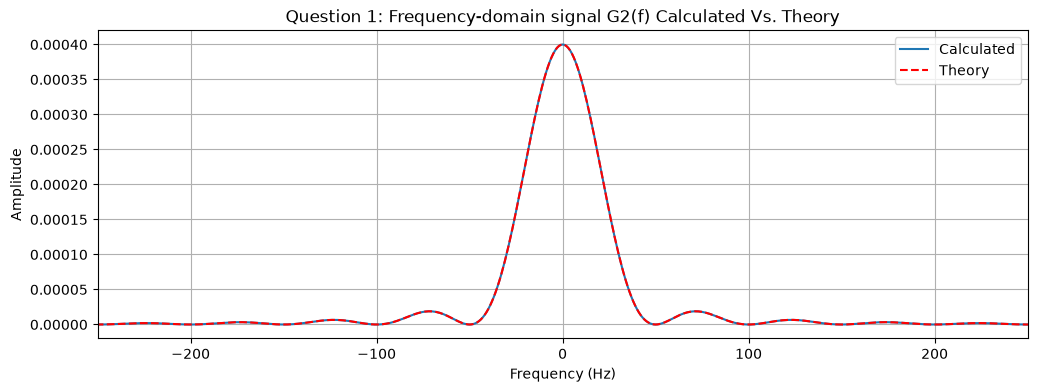

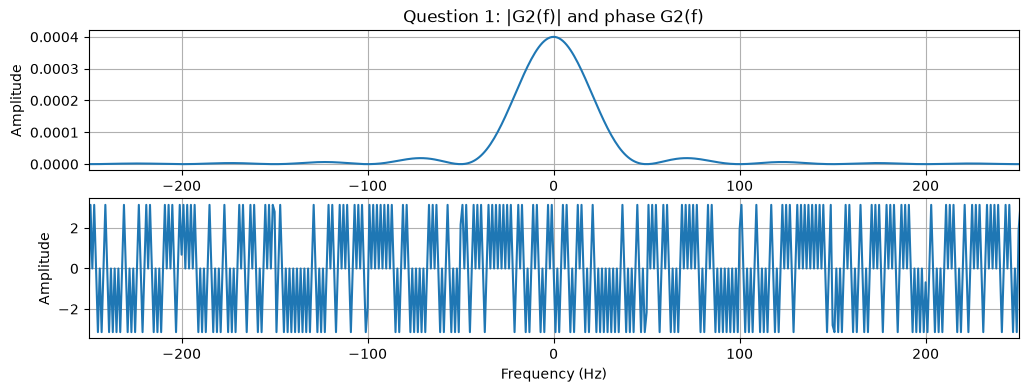

In [24]:
# 1.1 Parameters
fs_q1 = 10000
dt_q1 = 1.0 / fs_q1
t_q1 = np.arange(-0.5, 0.5, dt_q1)
A_q1 = 1.0
T_q1 = 0.02  # 20 ms

def rect_pulse(t, T):
    """Returns rect(t / T), equal to 1 for |t| < T/2 and 0 otherwise."""
    return np.where(np.abs(t) < T / 2.0, 1.0, 0.0)

# TODO: Construct g1(t) and compute g2(t) via numerical integration of g1(t)
g1 = A_q1 * (rect_pulse(t = t_q1 + T_q1/2.0, T = T_q1) - rect_pulse(t = t_q1 - T_q1/2.0, T= T_q1))
g2 = np.cumsum(g1) / fs_q1

# TODO: Compute CTFT approximations G1(f) and G2(f) and compare |G2(f)| with AT^2 * sinc^2(f*T)
freqs_q1 = fftshift(fftfreq(len(t_q1), d=dt_q1))
G1_f = fftshift(fft(g1)) / fs_q1
G2_f = fftshift(fft(g2)) / fs_q1

G2_theory = A_q1*np.power(T_q1, 2)*np.power(np.sinc(freqs_q1*T_q1),2)

# TODO: Plot time-domain signals (g1, g2) and frequency-domain spectra (|G1|, |G2| vs theory)

# g1(t):
plt.figure()
plt.plot(t_q1, g1)
plt.xlabel("Time (second)"); plt.ylabel("Amplitude"); plt.title("Question 1: Time-domain signal g1(t)")
# g2(t)
plt.figure()
plt.plot(t_q1, g2)
plt.xlabel("Time (second)"); plt.ylabel("Amplitude"); plt.title("Question 1: Time-domain signal g2(t)")

#G1(f)
plt.figure()
plt.plot(freqs_q1, abs(G1_f))
plt.xlabel("Frequency (Hz)"); plt.ylabel("Amplitude"); plt.title("Question 1: Frequency-domain signal G1(f)")
plt.xlim([-250,250])

# G2(f)
plt.figure()
plt.plot(freqs_q1, abs(G2_f), label = "Calculated")
plt.plot(freqs_q1, G2_theory,"r--" ,label = "Theory")
plt.legend()
plt.xlabel("Frequency (Hz)"); plt.ylabel("Amplitude"); plt.title("Question 1: Frequency-domain signal G2(f) Calculated Vs. Theory")
plt.xlim([-250,250])


# G2(f) and phase<G2(f)
plt.figure()
plt.subplot(2,1,1)
plt.plot(freqs_q1, abs(G2_f), label = "Calculated")
plt.xlabel("Frequency (Hz)"); plt.ylabel("Amplitude"); plt.title("Question 1: |G2(f)| and phase G2(f)")
plt.xlim([-250,250])


plt.subplot(2,1,2)
plt.plot(freqs_q1, np.angle(G2_f))
plt.xlabel("Frequency (Hz)"); plt.ylabel("Amplitude");
plt.xlim([-250,250])



### 1.2. Time Scaling, Rayleigh's Energy Theorem, and Bandwidth Metrics
Consider a simple rectangular pulse $p_T(t) = A \, \text{rect}(t/T)$ and a double-sided exponential pulse $x_a(t) = e^{-\alpha |t|}$.

1. **Rayleigh's Energy Theorem:** For $p_T(t)$ with $A=2, T=0.01\text{ s}$ and $x_a(t)$ with $\alpha = 100\text{ s}^{-1}$, compute the energy in the time domain ($E_t = \int |g(t)|^2 dt$) and in the frequency domain ($E_f = \int |G(f)|^2 df$) and print the relative error between $E_t$ and $E_f$.
2. **Bandwidth Metrics & Time Scaling:** Write a function `compute_bandwidths(freqs, G_f, is_rect_pulse=True)` that calculates three bandwidth measures for positive frequencies ($f \ge 0$):
   - **3-dB Bandwidth ($B_{3\text{dB}}$):** The frequency where $|G(f)|$ first drops to $\frac{|G(0)|}{\sqrt{2}}$.
   - **Null-to-Null Bandwidth ($B_{\text{null}}$):** The frequency of the first spectral zero ($|G(f)| = 0$, applicable to $\text{sinc}$ spectra).
   - **RMS Bandwidth ($W_{\text{rms}}$):**
     $$W_{\text{rms}} = \left[ \frac{\int_{-\infty}^{\infty} f^2 |G(f)|^2 df}{\int_{-\infty}^{\infty} |G(f)|^2 df} \right]^{1/2}$$
3. Evaluate and compare $B_{3\text{dB}}$, $B_{\text{null}}$, and $W_{\text{rms}}$ for a rectangular pulse $p_T(t)$ vs. a triangular pulse $g_2(t)$ across three pulse widths: $T \in \{10\text{ ms}, 20\text{ ms}, 40\text{ ms}\}$.

In [25]:
def verify_rayleigh_theorem(sig, G_f, dt, df):
    """
    Computes time-domain energy and frequency-domain energy to verify Rayleigh's theorem.
    """
    power_sig = abs(sig)**2
    power_G_f = abs(G_f)**2
    E_time = np.sum(power_sig)*dt # TODO: Integral of |sig(t)|^2 dt
    E_freq = np.sum(power_G_f)*df # TODO: Integral of |G(f)|^2 df
    return E_time, E_freq



def compute_bandwidths(freqs, G_f):
    """
    Computes 3-dB bandwidth, first-null bandwidth, and RMS bandwidth.
    """
    zero_tol = 1e-4

    mag = abs(G_f)
    df = freqs[1] - freqs[0]

    # Mask only positive frequencies
    pos_mask = freqs >=0
    f_pos = freqs[pos_mask]
    mag_pos = mag[pos_mask]

    # TODO: Implement B_3dB, B_null, and W_rms calculation

    # =======B_3dB==============

    dc_mag = mag_pos[0]
    mag_in_3dB = dc_mag / np.sqrt(2)
    idx_3dB = np.where(mag_pos <= mag_in_3dB)[0][0]
    B_3dB = f_pos[idx_3dB]

    #==========B_null===========
    
    null_indices = np.where(mag_pos <= zero_tol)[0]
    if len(null_indices) >0:
        B_null = f_pos[null_indices[0]]
    else:
        B_null = np.nan

    #===========W_rms=========
    
    energy_density = mag**2
    W_rms = np.sqrt(np.sum((freqs**2) * energy_density) * df / (np.sum(energy_density) * df))


    return B_3dB, B_null, W_rms


#   Rayleigh's energy Theorem:

p_T = 2*rect_pulse(t_q1, T = 0.01)
p_f = fftshift(fft(p_T)) /fs_q1
x_a = np.exp(-100*abs(t_q1))
x_f = fftshift(fft(x_a)) / fs_q1
df = freqs_q1[1] - freqs_q1[0]
E_p_T = verify_rayleigh_theorem(p_T,p_f, dt_q1, df)
E_x_a = verify_rayleigh_theorem(x_a, x_f, dt_q1, df)
error = [abs(E_p_T[1]-E_p_T[0]), abs(E_x_a[1] - E_x_a[0])]
print("Pulse Signal: ",error[0], "\n x_a: ", error[1])
# TODO: Run bandwidth comparison for T in [0.01, 0.02, 0.04] seconds and print a summary table

header = f"{'Pulse Type':<14} | {'T (ms)':<6} | {'B_3dB (Hz)':<11} | {'B_null (Hz)':<12} | {'W_rms (Hz)':<11}"
print(header)

for T in [0.01, 0.02, 0.04]:
    tri_sig = np.maximum(1 - np.abs(t_q1) / T,0)
    pulse_sig = 2*rect_pulse(t_q1, T = T)
    pulse_sig_f = fftshift(fft(pulse_sig)) / fs_q1
    tri_sig_f = fftshift(fft(tri_sig)) / fs_q1
    b3_r, bn_r, w_r = compute_bandwidths(freqs_q1, pulse_sig_f)
    b3_t, bn_t, w_t = compute_bandwidths(freqs_q1, tri_sig_f)

    print(f"{'Rectangular':<14} | {T*1000:<6.0f} | {b3_r:<11.2f} | {bn_r:<12.2f} | {w_r:<11.2f}")
    print(f"{'Triangular':<14} | {T*1000:<6.0f} | {b3_t:<11.2f} | {bn_t:<12.2f} | {w_t:<11.2f}")
    print("-" * len(header))

Pulse Signal:  6.938893903907228e-18 
 x_a:  3.469446951953614e-18
Pulse Type     | T (ms) | B_3dB (Hz)  | B_null (Hz)  | W_rms (Hz) 
Rectangular    | 10     | 45.00       | 100.00       | 265.01     
Triangular     | 10     | 32.00       | 91.00        | 27.63      
------------------------------------------------------------------
Rectangular    | 20     | 23.00       | 50.00        | 187.39     
Triangular     | 20     | 16.00       | 47.00        | 13.80      
------------------------------------------------------------------
Rectangular    | 40     | 12.00       | 25.00        | 132.51     
Triangular     | 40     | 8.00        | 24.00        | 6.90       
------------------------------------------------------------------


**Question 1 Analysis:**
- *How does doubling the pulse duration $T$ affect $B_{3\text{dB}}$, $B_{\text{null}}$, and $W_{\text{rms}}$?*
- *Why does the triangular pulse $g_2(t)$ have a significantly smaller RMS bandwidth $W_{\text{rms}}$ (faster sidelobe roll-off) than the rectangular pulse $p_T(t)$, and how does this relate to the differentiation/integration property of the Fourier Transform?*

**Answer:**
## Question 1
As expected, increasing T causes decreasing in the band width. 
$$x(t/T) \to T X(T f)$$
For $B_{3dB}$ and $B_{null}$ the effect is the same, doubling T halves them.
But for $W_{rms}$ has different effect, doubling T reduces the $W_{rms}$ by factor $\sqrt{2}$.
## Question 2
The rectangular pulse has discontinuities at its edges. Sharp edges requires high frequency band to reperesent the signal in frequency domain. Integrating pulse to get $g_2$ removes the discontinuities and makes the signal smooth. Smoother signal requires smaller band width. 
But why this is more obvoius for $W_{rms}$?

In this method, integrating $f^2 |G(f)|^2$ puts higher wights on higher frequencies.  $g_2$ has smaller high-frequency components so as expected has much smaller $W_{rms}$.



---
# Question 2: Multi-Channel Frequency-Division Multiplexing (FDM), Practical Filter Design, and Hilbert Transform (55 Points)

In a multi-user communication system, several baseband signals can share a common medium by shifting each user's spectrum to a dedicated carrier frequency using the **Frequency Shifting (Modulation) Property**:
$$m_k(t)\cos(2\pi f_{c,k} t) \Longleftrightarrow \frac{1}{2}\Big[ M_k(f - f_{c,k}) + M_k(f + f_{c,k}) \Big]$$

At the receiver, extracting a desired user requires translating the target channel to a shared **Intermediate Frequency ($f_{\text{IF}}$)** and applying a **Bandpass Filter (BPF)**. As covered in the lectures, practical filters cannot achieve an ideal "brick-wall" response and exhibit different trade-offs in passband ripple, transition width, and **Group Delay ($\tau_g(f) = -\frac{1}{2\pi}\frac{d\theta(f)}{df}$)** depending on their family (**Butterworth**, **Chebyshev**, or **Bessel**).

Furthermore, using the **Hilbert Transform** ($H_Q(f) = -j\,\text{sgn}(f)$), we can eliminate one of the two symmetric sidebands to form a **Single-Sideband (SSB)** signal, cutting the required transmission bandwidth in half!

### 2.1. Audio Processing, Upsampling, and 6-User FDM Multiplexing
1. Set the simulation sampling rate to $f_{\text{sim}} = 500\text{ kHz}$, duration $T = 10\text{ s}$ (or $5\text{ s}$ if memory-constrained), and baseband target sampling rate `target_sr = 8000` Hz.
2. Load 6 audio files from `audio_folder` (if no external audio files are present in the folder, the provided fallback generator automatically creates 6 distinct bandlimited speech-like/musical test signals so your notebook always runs seamlessly).
3. Upsample all 6 signals to $f_{\text{sim}} = 500\text{ kHz}$ and normalize their amplitude to $[-1, 1]$.
4. Modulate the 6 signals onto 6 carrier frequencies starting at `center_freq = 110 kHz` with channel bandwidth `target_sr = 8 kHz` and `guard_width = 2 kHz` (i.e., carrier spacing $\Delta f = 10\text{ kHz}$: $110, 120, 130, 140, 150, 160\text{ kHz}$).
5. Plot the spectrum of the composite FDM signal.

In [26]:
# Simulation Parameters
fs_simulation = 500000         # 500 kHz simulation sampling rate
duration      = 5              # Duration in seconds
target_sr     = 8000           # 8 kHz baseband sampling rate
center_freq   = 110000         # Starting carrier frequency (110 kHz)
guard_width   = 2000           # Guard band width (2 kHz)
num_samples   = int(fs_simulation * duration)
t = np.linspace(0, duration, num_samples, endpoint=False)

audio_folder = "./audio_files"

def load_or_generate_audio_signals(audio_folder, num_signals, target_sr, duration):
    """
    Loads up to num_signals audio files (.wav, .mp3, .flac) from audio_folder.
    If fewer than num_signals files exist, synthesizes distinct bandlimited signals (< 3.6 kHz).
    """
    target_samples = int(target_sr * duration)
    signals_base = []
    if os.path.exists(audio_folder):
        files = [f for f in os.listdir(audio_folder) if f.endswith(('.wav', '.mp3', '.flac'))]
        for f in sorted(files)[:num_signals]:
            y, sr = librosa.load(os.path.join(audio_folder, f), sr=target_sr)
            if len(y) < target_samples:
                y = np.pad(y, (0, target_samples - len(y)))
            else:
                y = y[:target_samples]
            signals_base.append(y)
            
    # Fallback synthesis if folder is empty or has fewer than 6 files
    t_low = np.linspace(0, duration, target_samples, endpoint=False)
    b_lp, a_lp = signal.butter(6, 3500 / (target_sr / 2), btype='low')
    np.random.seed(1403)
    while len(signals_base) < num_signals:
        idx = len(signals_base) + 1
        raw = (np.sin(2*np.pi*(250*idx)*t_low) * (1 + 0.5*np.cos(2*np.pi*idx*t_low)) +
               0.5*signal.chirp(t_low, f0=150*idx, t1=duration, f1=3000 - 200*idx))
        sig_filtered = signal.filtfilt(b_lp, a_lp, raw)
        signals_base.append(sig_filtered)
    return signals_base

def normalize_audio(audio):
    max_val = np.max(np.abs(audio))
    return audio / max_val if max_val > 0 else audio

# Load/generate 6 baseband signals and upsample to fs_simulation
baseband_8k = load_or_generate_audio_signals(audio_folder, 6, target_sr, duration)
audio_vectors = []
for sig in baseband_8k:
    # TODO: Upsample sig from target_sr to fs_simulation (e.g. librosa.resample or signal.resample_poly)
    up_sig = librosa.resample(sig, orig_sr= target_sr, target_sr= fs_simulation)
    audio_vectors.append(normalize_audio(up_sig[:num_samples]).astype(np.float32))
audio_vectors = np.array(audio_vectors)
print(f"Audio vectors shape: {audio_vectors.shape}")

Audio vectors shape: (6, 2500000)


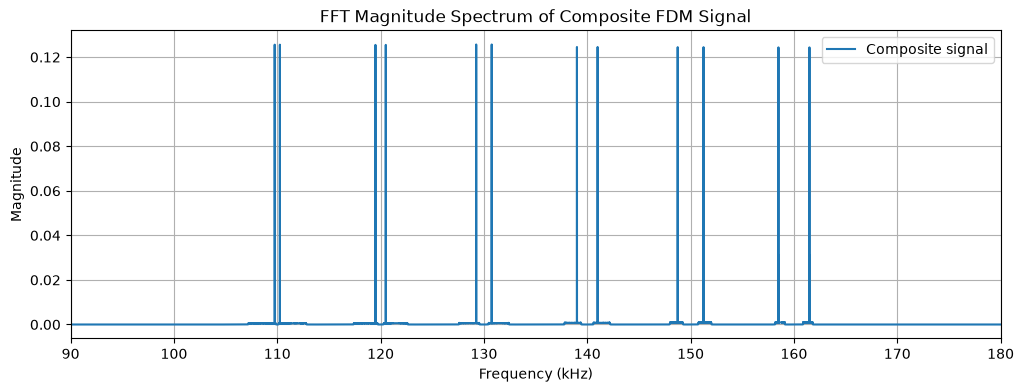

In [27]:
def modulate_signal(sig, t, f_0):
    """Modulates a baseband signal onto carrier cos(2 * pi * f_0 * t)."""
    # TODO
    return sig*np.cos(2*np.pi*f_0*t)

def modulate_all_signals(audio_vectors, fs_simulation, center_freq, target_sr, guard_width, t):
    """
    Modulates all 6 signals to their respective carrier frequencies and forms the composite FDM signal.
    """
    num_signals = len(audio_vectors)
    channel_spacing = target_sr + guard_width
    f_0_vector = np.array([center_freq + i * channel_spacing for i in range(num_signals)])  # TODO: Array of 6 carrier frequencies starting at center_freq
    composite_signal = np.zeros_like(t, dtype=np.float32)
    
    for i, (audio, f_0) in enumerate(zip(audio_vectors, f_0_vector)):
        composite_signal += modulate_signal(audio, t, f_0)
        
    return composite_signal, f_0_vector

composite_signal, center_freqs = modulate_all_signals(audio_vectors, fs_simulation, center_freq, target_sr, guard_width, t)

# TODO: Plot the FFT magnitude spectrum of composite_signal in the [90 kHz, 180 kHz] range
N = len(composite_signal)
freqs = fftshift(fftfreq(N, d=1 / fs_simulation))
spectrum = np.abs(fftshift(fft(composite_signal))) / N


plt.figure()
plt.plot(freqs / 1000, spectrum, label="Composite signal")
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude")
plt.title("FFT Magnitude Spectrum of Composite FDM Signal")
plt.legend()
plt.xlim([90, 180])
plt.show()

### 2.2. Superheterodyne Receiver and Filter Family Comparison (Butterworth vs. Chebyshev I vs. Bessel)
To demultiplex each channel using a single fixed Intermediate Frequency (IF) filter centered at $f_{\text{IF}} = 80\text{ kHz}$:
1. **Frequency Translation to IF:** Multiply `composite_signal` by $2\cos(2\pi |f_c - f_{\text{IF}}| t)$.
2. **IF Bandpass Filtering:** Apply a 4th-order bandpass filter centered at $f_{\text{IF}} = 80\text{ kHz}$ with bandwidth $B = 8\text{ kHz}$.
3. **Baseband Demodulation:** Multiply the IF signal by $2\cos(2\pi f_{\text{IF}} t)$ and pass it through a 4th-order low-pass filter with cutoff $f_{\text{LP}} = 4\text{ kHz}$.

**Filter Comparison Task:**
- Implement the receiver using causal filtering (`scipy.signal.lfilter`) for three classical filter families studied in class:
  1. **Butterworth** (`signal.butter`, maximally flat magnitude)
  2. **Chebyshev Type I** (`signal.cheby1` with `rp = 1.5` dB passband ripple, sharp transition band)
  3. **Bessel** (`signal.bessel`, maximally flat group delay / linear phase)
- Plot the **Magnitude Response $|H(f)|$ (in dB)** and **Group Delay $\tau_g(f) = -\frac{1}{2\pi}\frac{d\theta(f)}{df}$ (in ms)** of the three low-pass filters over $[0, 8\text{ kHz}]$.
- Compensate for the average bulk delay of each causal filter (or compare with zero-phase `filtfilt`) and calculate the Mean Squared Error (MSE) of the extracted channels for all three filter types.

/tmp/ipykernel_27552/1945390271.py:38: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim([0, 8e3])


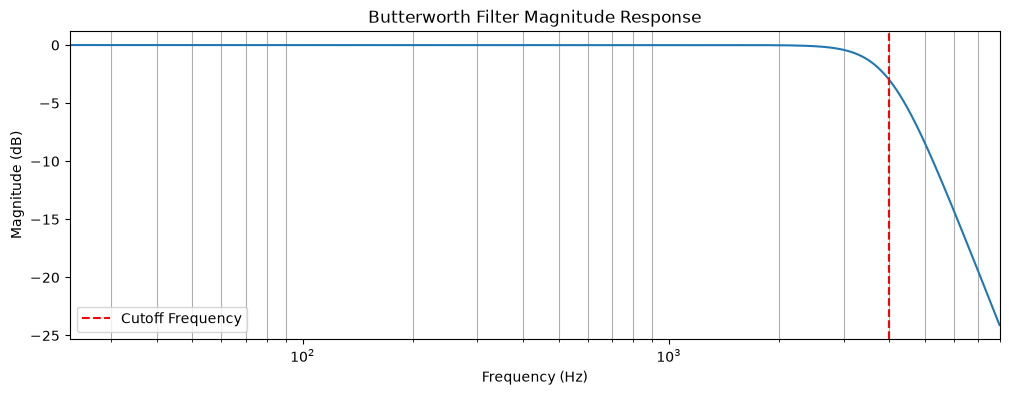

/tmp/ipykernel_27552/1945390271.py:42: UserWarning: The filter's denominator is extremely small at frequencies [3.137, 3.138, 3.138, 3.139, 3.139, 3.139, 3.140, 3.140, 3.140, 3.141, 3.141], around which a singularity may be present
  w_gd, gd_samples = signal.group_delay((b, a), w=8192, fs=fs_simulation)


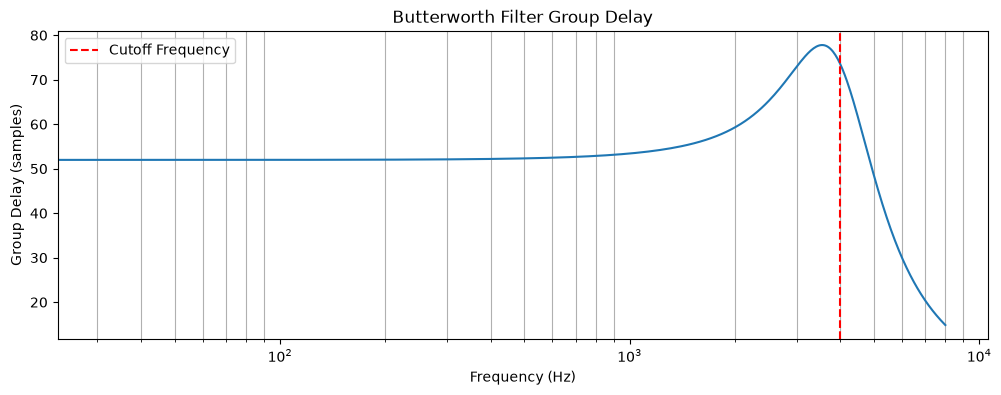

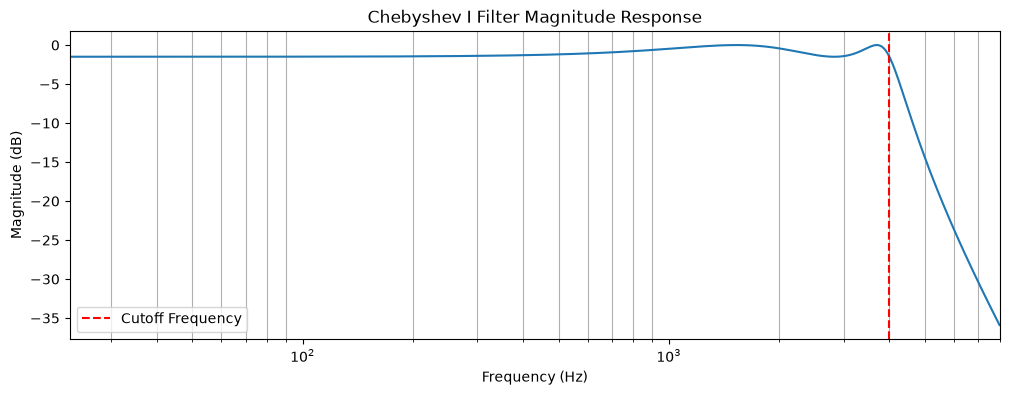

/tmp/ipykernel_27552/1945390271.py:42: UserWarning: The filter's denominator is extremely small at frequencies [3.135, 3.136, 3.136, 3.137, 3.137, 3.137, 3.138, 3.138, 3.139, 3.139, 3.139, 3.140, 3.140, 3.140, 3.141, 3.141], around which a singularity may be present
  w_gd, gd_samples = signal.group_delay((b, a), w=8192, fs=fs_simulation)


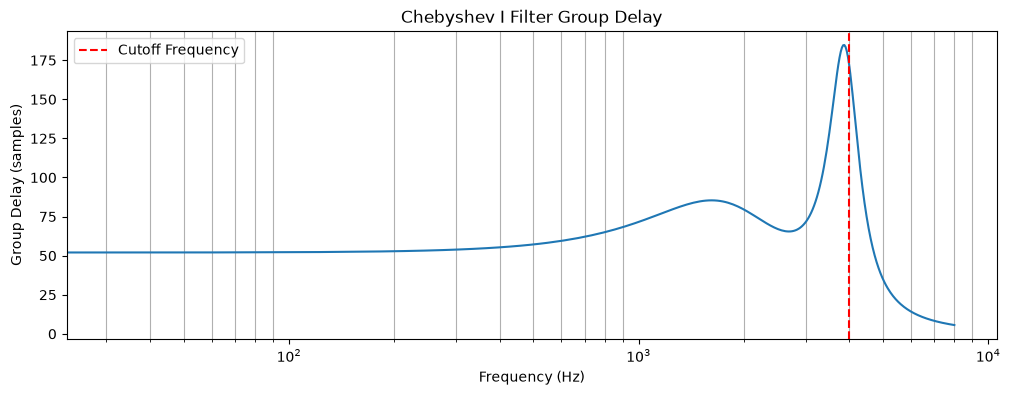

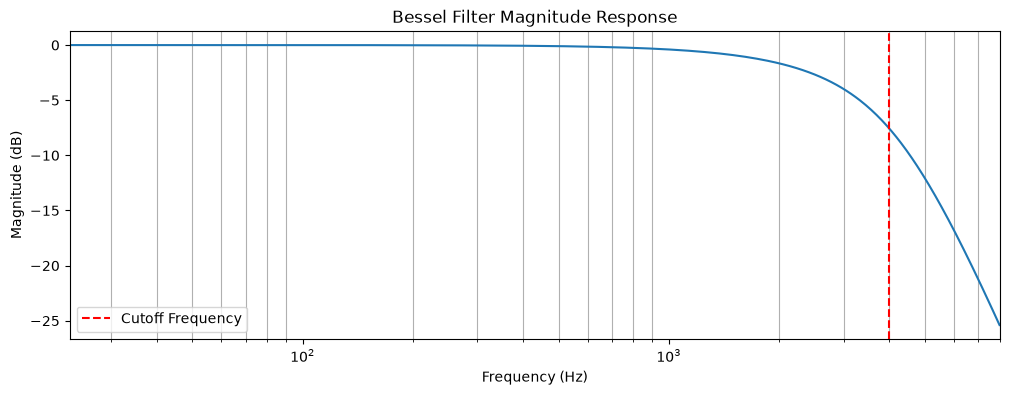

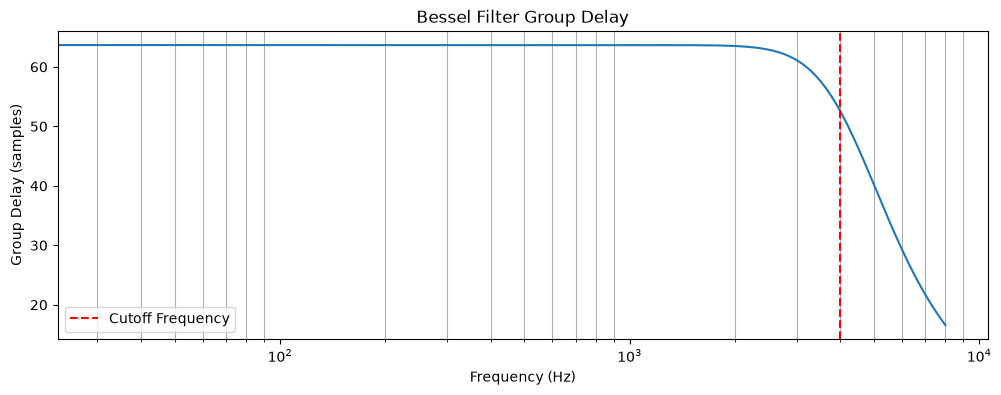

MSE comparison
Filter          Ch1          Ch2          Ch3          Ch4          Ch5          Ch6         
Butterworth     2.372351e-05 8.753816e-06 3.360779e-06 1.637538e-06 1.215843e-06 1.078184e-06
Chebyshev I     7.509910e-03 5.515372e-03 2.795743e-03 1.048629e-03 4.716731e-04 3.450177e-04
Bessel          5.818049e-03 4.778985e-03 3.593608e-03 2.449060e-03 1.477203e-03 1.193498e-03


In [28]:
def design_filter(filter_type, order, cutoff_norm, btype='low', rp=1.5):
    """
    Returns (b, a) coefficients for 'butter', 'cheby1', or 'bessel' filter.
    """
    if filter_type == 'butter':
        return signal.butter(order, cutoff_norm, btype=btype)
    elif filter_type == 'cheby1':
        return signal.cheby1(order, rp, cutoff_norm, btype=btype)
    elif filter_type == 'bessel':
        return signal.bessel(order, cutoff_norm, btype=btype, norm='phase')
    else:
        raise ValueError("Unknown filter_type")

# TODO: Plot Magnitude Response and Group Delay of 4th-order Butterworth, Chebyshev-I, and Bessel LPFs (fc = 4 kHz)

filter_types = {
    "Butterworth": "butter",
    "Chebyshev I": "cheby1",
    "Bessel": "bessel"
}

fc = 4000  # 4 kHz
nyq = fs_simulation / 2.0
for name, ftype in filter_types.items():
    cutoff_norm = fc / nyq    # Cutoff frequency normalized to Nyquist-It is a number between 0 and 1
    b, a = design_filter(ftype, 4, cutoff_norm, btype='low')
    w, h = signal.freqz(b, a, worN=8192, fs=fs_simulation)
    mask = w < 8e3
    # Magnitude Response
    plt.figure()
    plt.semilogx(w[mask], 20 * np.log10(abs(h[mask])))
    plt.title(f"{name} Filter Magnitude Response")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(which='both', axis='both')
    plt.axvline(fc, color='red', linestyle='--', label='Cutoff Frequency')
    plt.legend()
    plt.xlim([0, 8e3])
    plt.show()

    # Group Delay
    w_gd, gd_samples = signal.group_delay((b, a), w=8192, fs=fs_simulation)
    plt.figure()
    plt.semilogx(w_gd[mask], gd_samples[mask])
    plt.title(f"{name} Filter Group Delay")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Group Delay (samples)")
    plt.grid(which='both', axis='both')
    plt.axvline(fc, color='red', linestyle='--', label='Cutoff Frequency')
    plt.legend()
    plt.show()

def extract_channel_if(composite_signal, fs_simulation, fc, f_if, bandwidth, t, filter_type='butter'):
    """
    Translates channel at fc to f_if, bandpass filters, demodulates to baseband, and low-pass filters.
    """
    nyq = fs_simulation / 2.0
    # 1. Translate to IF
    translated_signal = composite_signal * np.cos(2 * np.pi * (fc - f_if) * t)
    
    # 2. IF Bandpass Filter
    low_cut = (f_if - bandwidth / 2.0) / nyq
    high_cut = (f_if + bandwidth / 2.0) / nyq
    b_bp, a_bp = design_filter(filter_type, 4, [low_cut, high_cut], btype='band')
    if_filtered = signal.filtfilt(b_bp, a_bp, translated_signal)
    
    # 3. Demodulate to baseband and LPF
    demod_raw = if_filtered * np.cos(2 * np.pi * f_if * t)
    b_lp, a_lp = design_filter(filter_type, 4, (bandwidth / 2.0) / nyq, btype='low')
    baseband_sig = signal.filtfilt(b_lp, a_lp, demod_raw)
    
    return normalize_audio(baseband_sig)

# TODO: Extract all 6 channels for each filter type and compare their MSEs against audio_vectors
f_if = 80000
channel_bandwidth = target_sr

mse_results = {}
extracted_channels = {}

for filter_name, filter_type_name in filter_types.items():
    channel_mse = []
    channel_outputs = []

    for i, carrier in enumerate(center_freqs):
        recovered = extract_channel_if(
            composite_signal=composite_signal, fs_simulation=fs_simulation, fc=int(carrier), f_if=f_if, bandwidth=channel_bandwidth, t=t, filter_type=filter_type_name
        )

        recovered = recovered[:audio_vectors.shape[1]]
        channel_outputs.append(recovered)
        channel_mse.append(mean_squared_error(audio_vectors[i], recovered))

    extracted_channels[filter_name] = np.asarray(channel_outputs)
    mse_results[filter_name] = channel_mse

print("MSE comparison")
print(f"{'Filter':<15} " + " ".join(f"Ch{i + 1:<10}" for i in range(6)))

for filter_name, values in mse_results.items():
    print(
        f"{filter_name:<15} " +
        " ".join(f"{value:<10.6e}" for value in values)
    )


### 2.3. Hilbert Transform and Single-Sideband (SSB) Bandwidth Halving
From the lecture notes, the **Hilbert Transform** $\hat{m}(t)$ shifts the phase of all positive frequency components by $-90^\circ$ ($H_Q(f) = -j\,\text{sgn}(f)$) without altering the magnitude spectrum ($|\hat{M}(f)| = |M(f)|$), and satisfies the orthogonality property:
$$\int_{-\infty}^{\infty} m(t)\,\hat{m}(t)\,dt = 0$$

Moreover, we can construct an **Upper-Sideband (USB)** modulated signal that occupies **half the bandwidth** of DSB-SC:
$$s_{\text{USB}}(t) = m(t)\cos(2\pi f_c t) - \hat{m}(t)\sin(2\pi f_c t)$$

1. Using `scipy.signal.hilbert` on `audio_vectors[0]`, extract $\hat{m}_1(t) = \text{Im}\{\text{hilbert}(m_1(t))\}$.
2. Numerically verify that $|\hat{M}_1(f)| = |M_1(f)|$ and that $\langle m_1(t), \hat{m}_1(t) \rangle \approx 0$.
3. Generate $s_{\text{USB}}(t)$ at $f_c = 110\text{ kHz}$ and plot its spectrum alongside the standard DSB-SC signal $m_1(t)\cos(2\pi f_c t)$ to verify that the lower sideband ($f < 110\text{ kHz}$) is completely suppressed.

Inner product <m1, m1_hat>: 2.6931763486004456e-09


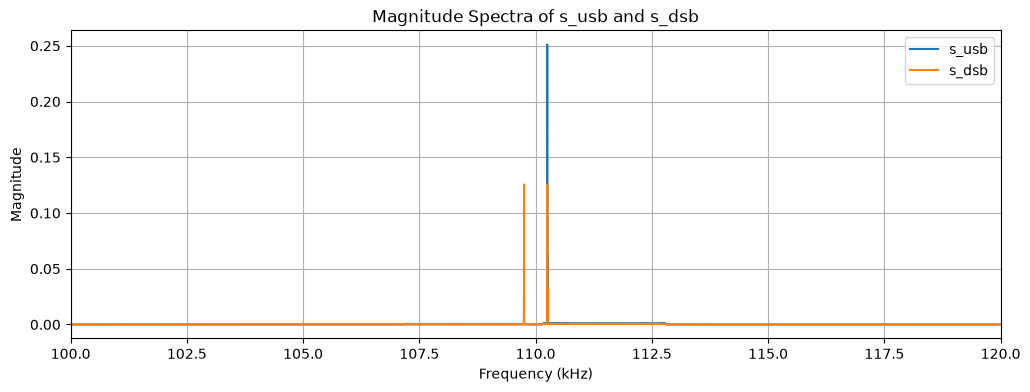

In [29]:
m1 = audio_vectors[0]

# TODO: Compute Hilbert transform m1_hat using np.imag(signal.hilbert(m1))
m1_hat = np.imag(signal.hilbert(m1))

# TODO: Check orthogonality inner product <m1(t), m1_hat(t)>
inner_prod = np.sum(m1 * m1_hat) * (1 / fs_simulation)  # Numerical integration.
print(f"Inner product <m1, m1_hat>: {inner_prod}")

# TODO: Construct s_dsb and s_usb at fc = 110 kHz and plot their magnitude spectra in [100 kHz, 120 kHz]
s_usb = m1 * np.cos(2 * np.pi * center_freqs[0] * t) - m1_hat * np.sin(2 * np.pi * center_freqs[0] * t)
s_dsb = m1 * np.cos(2 * np.pi * center_freqs[0] * t)

N = len(s_usb)
freqs = fftshift(fftfreq(N, d=1 / fs_simulation))
s_usb_spectrum = np.abs(fftshift(fft(s_usb))) / N
s_dsb_spectrum = np.abs(fftshift(fft(s_dsb))) / N
plt.figure()
plt.plot(freqs / 1000, s_usb_spectrum, label="s_usb")
plt.plot(freqs / 1000, s_dsb_spectrum, label="s_dsb")
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude")
plt.title("Magnitude Spectra of s_usb and s_dsb")
plt.xlim([100, 120])
plt.legend()
plt.show()

**Question 2 Analysis:**
- *Compare the Magnitude Response and Group Delay plots of the Butterworth, Chebyshev Type I, and Bessel filters. Which filter has the sharpest roll-off, and which filter causes the least phase/group-delay distortion to transient waveforms?*
- *Why does subtracting $\hat{m}(t)\sin(2\pi f_c t)$ from $m(t)\cos(2\pi f_c t)$ cancel the lower sideband?*

**Answer:**

## Qustion 1

**Chebyshev Type I**, provides the sharpest roll-off at the cutoff frequency, though this comes at the cost of a severe group delay spike near the cutoff edge.

**Bessel** exhibits the gentlest roll-off, but features a maximally flat group delay.

**Butterworth** offers a compromise between the two, having a maximally flat passband magnitude without ripple and moderate roll-off and group delay variation.
## Question 2
The Hilbert transform $\hat{m}(t)$ shifts all positive frequency components of $m(t)$ by $-90^\circ$ and negative frequencies by $+90^\circ$.
Subtracting $\hat{m}(t)\sin(2\pi f_c t)$ from $m(t)\cos(2\pi f_c t)$ therefore causes the in-phase lower sidebands to cancel out completely while the upper sidebands add constructively.

---
# Question 3: Non-Linear Distortion, THD, Intermodulation, and Link Power Budget (60 Points)

Real-world communication amplifiers and channels exhibit **Non-Linear Distortion** when driven by large input signals, modeled by a memoryless polynomial:
$$y(t) = a_1 x(t) + a_2 x^2(t) + a_3 x^3(t)$$

As shown in the lecture slides:
- For a **single-tone input** $x(t) = A\cos(2\pi f_0 t)$, non-linearity creates harmonics at $2f_0, 3f_0, \dots$, quantified by the **Total Harmonic Distortion (THD)**:
  $$\text{THD} = \frac{\sqrt{B_2^2 + B_3^2 + \dots}}{|B_1|}$$
- For a **two-tone or multi-channel input**, the cubic term $a_3 x^3(t)$ generates **in-band intermodulation components** at $2f_1 - f_2$ and $2f_2 - f_1$ that fall directly onto adjacent channels.
- Furthermore, physical channels attenuate the signal according to the **Free-Space Path Loss (FSPL)** formula:
  $$L_{\text{dB}} = 92.4 + 20\log_{10}(f_{\text{GHz}}) + 20\log_{10}(d_{\text{km}})$$

### 3.1. Single-Tone Harmonic Distortion (THD) and Two-Tone Intermodulation
Let the polynomial amplifier parameters be $a_1 = 1.0$, $a_2 = 0.12$, and $a_3 = -0.08$.

1. **Single-Tone THD:** Apply $x_1(t) = A \cos(2\pi f_0 t)$ with $f_0 = 20\text{ kHz}$ to the amplifier. Compute the output spectrum, measure the fundamental amplitude $|B_1|$ at $f_0$, second harmonic $|B_2|$ at $2f_0$, and third harmonic $|B_3|$ at $3f_0$. Plot **THD (%)** as a function of input amplitude $A \in [0.1, 2.0]$.
2. **Two-Tone Intermodulation Test:** Apply $x_2(t) = A\cos(2\pi f_1 t) + A\cos(2\pi f_2 t)$ with $f_1 = 20\text{ kHz}$, $f_2 = 22\text{ kHz}$, and $A = 1.0$. Plot the output spectrum (in dB) from $0\text{ kHz}$ to $75\text{ kHz}$ and label all generated frequencies $m f_1 + n f_2$ ($0, f_2-f_1, 2f_1-f_2, f_1, f_2, 2f_2-f_1, 2f_1, f_1+f_2, 2f_2, 3f_1, 2f_1+f_2, f_1+2f_2, 3f_2$), reproducing the exact spectral structure from the lecture slides.

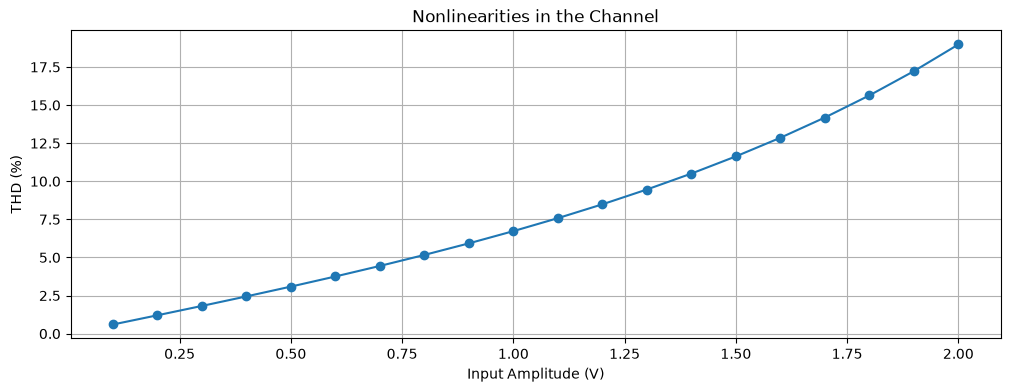

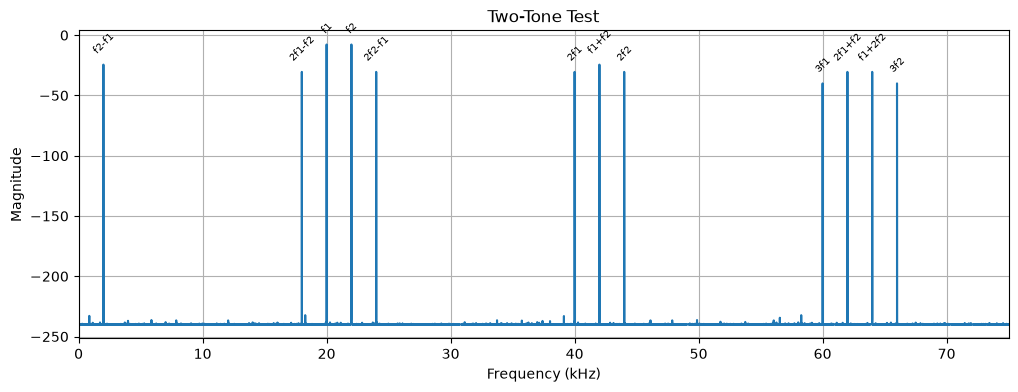

In [30]:
a1, a2, a3 = 1.0, 0.12, -0.08

def nonlinear_channel(x, a1=1.0, a2=0.12, a3=-0.08):
    """Applies polynomial non-linearity y(t) = a1*x + a2*x^2 + a3*x^3."""
    # TODO
    return np.polyval([a3, a2, a1,0], x)

def calculate_thd(y, fs, f0):
    """
    Computes 2nd-order HD, 3rd-order HD, and Total Harmonic Distortion (THD)
    from the FFT magnitude peaks at f0, 2*f0, and 3*f0.
    """
    # TODO: Extract spectral magnitudes B1, B2, B3 and compute THD
    N = len(y)
    freqs = fftshift(fftfreq(N, d=1/fs))
    B1 = np.abs(fftshift(fft(y)))[np.argmin(np.abs(freqs - f0))]
    B2 = np.abs(fftshift(fft(y)))[np.argmin(np.abs(freqs - 2*f0))]
    B3 = np.abs(fftshift(fft(y)))[np.argmin(np.abs(freqs - 3*f0))]
    thd = np.sqrt(B2**2 + B3**2) / B1 * 100
    return thd

# TODO: 1. Sweep input amplitude A from 0.1 to 2.0 and plot THD (%) vs. A
A = np.linspace(0.1, 2.0, 20)
thd_values = []
for amp in A:
    test_signal = amp * np.cos(2 * np.pi * 20000 * t)  # 20 kHz test tone
    output_signal = nonlinear_channel(test_signal, a1, a2, a3)
    thd = calculate_thd(output_signal, fs_simulation, 20000)
    thd_values.append(thd)

plt.figure()
plt.plot(A, thd_values, 'o-')
plt.xlabel('Input Amplitude (V)')
plt.ylabel('THD (%)')
plt.title('Nonlinearities in the Channel')
plt.show()

# TODO: 2. Run Two-Tone test (f1 = 20 kHz, f2 = 22 kHz) and plot the dB spectrum showing all mf1 + nf2 components

f1 = 2e4
f2 = 22e3

x_2 = np.cos(2 * np.pi * 20000 * t) + np.cos(2 * np.pi * 22000 * t)
y_2 = nonlinear_channel(x_2, a1, a2, a3)

N = len(y_2)
freqs = fftshift(fftfreq(N, d=1 / fs_simulation))
y_2_spectrum = np.abs(fftshift(fft(y_2))) / N
spec_db = 20 * np.log10(y_2_spectrum + 1e-12)
plt.figure()
plt.plot(freqs / 1000, spec_db)
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude")
plt.title("Two-Tone Test")
plt.xlim([0, 75])

components = [
    (f2 - f1, "f2-f1"), (2*f1 - f2, "2f1-f2"),
    (f1, "f1"), (f2, "f2"), (2*f2 - f1, "2f2-f1"),
    (2*f1, "2f1"), (f1 + f2, "f1+f2"), (2*f2, "2f2"),
    (3*f1, "3f1"), (2*f1 + f2, "2f1+f2"), (f1 + 2*f2, "f1+2f2"), (3*f2, "3f2")
]

for f_comp, label in components:
    idx = np.argmin(np.abs(freqs - f_comp))
    plt.annotate(label, xy=(f_comp / 1000, spec_db[idx]),
                 xytext=(0, 8), textcoords='offset points',
                 ha='center', fontsize=7, rotation=45)

plt.show()

### 3.2. 3-Channel FDM in a Non-Linear Channel and Link Budget Analysis
1. Select the first 3 audio signals from Question 2 (`audio_vectors[:3]`) and modulate them onto $f_{c1} = 110\text{ kHz}$, $f_{c2} = 120\text{ kHz}$, and $f_{c3} = 130\text{ kHz}$.
2. Pass the 3-channel composite signal through `nonlinear_channel` under two cases:
   - **Case I (Quadratic Only):** $a_1 = 1.0, a_2 = 0.15, a_3 = 0.0$
   - **Case II (Quadratic + Cubic):** $a_1 = 1.0, a_2 = 0.15, a_3 = -0.10$
3. Extract all 3 channels using your IF receiver (`extract_channel_if`) and compute the MSE for each channel in both cases. Observe which channel suffers the worst distortion in Case II ($2f_{c2} - f_{c1} = f_{c3}$ and $f_{c1} + f_{c3} - f_{c2} = f_{c2}$)!
4. **Link Power Budget Integration:** Suppose this 3-channel signal is transmitted over a terrestrial microwave radio link of distance $d = 25\text{ km}$ operating at RF frequency $f_{\text{RF}} = 6\text{ GHz}$, with transmit antenna gain $g_T = 32\text{ dBi}$ and receive antenna gain $g_R = 32\text{ dBi}$. If the receiver requires a minimum received power (sensitivity) of $P_{\text{sens}} = -75\text{ dBm}$, compute the Free-Space Path Loss $L_{\text{dB}}$ and the minimum required transmitter output power in **dBm** and **Watts**.

In [31]:
# Modulate first 3 audio signals at 110, 120, 130 kHz
carrier_freqs_3 = [110000, 120000, 130000]
selected_audio_3 = audio_vectors[:3]

# TODO: Pass the 3-channel signal through Case I (a3=0) and Case II (a3=-0.10),
# extract the baseband channels, and compare their MSEs.
audio_vectors_3 = np.array([modulate_signal(sig, t, f) for sig, f in zip(selected_audio_3, carrier_freqs_3)])
composite_signal_3 = np.sum(audio_vectors_3, axis=0)
nonlinear_case_I = nonlinear_channel(composite_signal_3, a1=1.0, a2=0.15, a3=0.0)
nonlinear_case_II = nonlinear_channel(composite_signal_3, a1=1.0, a2=0.15, a3=-0.10)
extracted_case_I = np.array([extract_channel_if(nonlinear_case_I, fs_simulation, fc, f_if, channel_bandwidth, t) for fc in carrier_freqs_3])
extracted_case_II = np.array([extract_channel_if(nonlinear_case_II, fs_simulation, fc, f_if, channel_bandwidth, t) for fc in carrier_freqs_3])

# Compute MSE for each case
mse_case_I = np.mean((extracted_case_I - selected_audio_3)**2, axis = 1)
mse_case_II = np.mean((extracted_case_II - selected_audio_3)**2, axis = 1)

for i, fc in enumerate(carrier_freqs_3):
    print(f"Ch {i+1} ({fc/1000:.0f} kHz) -> Case I MSE: {mse_case_I[i]:.4e} | Case II MSE: {mse_case_II[i]:.4e}")

# TODO: Compute Free-Space Path Loss L_dB and minimum required transmit power (in dBm and W)
d_km = 25.0
f_ghz = 6.0
g_t_db = 32.0
g_r_db = 32.0
p_sens_dbm = -75.0

L_db = 92.4 + 20 * np.log10(f_ghz) + 20 * np.log10(d_km)  # 135.92 dB
P_tx_min_dbm = p_sens_dbm + L_db - g_t_db - g_r_db        # -3.08 dBm
P_tx_min_watts = 10 ** (P_tx_min_dbm / 10) / 1000         # 0.000492 W (~0.49 mW)
print(f"Free-Space Path Loss: {L_db:.2f} dB")
print(f"Minimum Transmit Power: {P_tx_min_dbm:.2f} dBm ({P_tx_min_watts:.4e} W)")


Ch 1 (110 kHz) -> Case I MSE: 2.3775e-05 | Case II MSE: 8.3846e-04
Ch 2 (120 kHz) -> Case I MSE: 8.6102e-06 | Case II MSE: 1.1085e-03
Ch 3 (130 kHz) -> Case I MSE: 3.2751e-06 | Case II MSE: 1.1721e-03
Free-Space Path Loss: 135.92 dB
Minimum Transmit Power: -3.08 dBm (4.9225e-04 W)


**Question 3 Analysis:**
- *Why does Case I ($a_2 \neq 0, a_3 = 0$) result in very low MSE after bandpass filtering when carrier frequencies are around $110\text{--}130\text{ kHz}$, whereas Case II ($a_3 \neq 0$) causes severe unfilterable in-band distortion?*
- *If we reduce the input signal amplitude before the amplifier (operating in the linear region to reduce THD and IMD), how does that impact our Link Power Budget and received power margin?*

**Answer:**


### Question 1
In Case I, the quadratic term $a_2 x^2(t)$ generates distortion products only at DC/baseband ($f_i - f_j \in [0, 20]\text{ kHz}$) and second-order sums ($f_i + f_j \in [220, 260]\text{ kHz}$), all of which fall far outside the $110\text{--}130\text{ kHz}$ passband and are easily removed by the IF bandpass filter.

In Case II, the cubic term $a_3 x^3(t)$ produces third-order intermodulation products ($2f_i - f_j$ and $f_i + f_j - f_k$) that land directly on top of the active carrier frequencies.

So, case II spectrally overlap with the desired signal inside the passband, the passband filter cannot sperate them, causing high MSE.

---
# Question 4: Two-Path Microwave Link, TDL Equalization, Auto/Cross-Correlation, and PSD (60 Points)

As studied in the **Microwave Links** and **Correlation & Spectral Density** sections of the course:
1. A two-path microwave radio link with a direct path and a ground-reflected path is modeled as:
   $$y(t) = K_1 x(t - t_{d1}) + K_2 x(t - t_{d2}) \quad \Longrightarrow \quad H_c(f) = K_1 e^{-j2\pi f t_{d1}} \left(1 + K e^{-j2\pi f \Delta t}\right)$$
   where $K = K_2 / K_1 \ll 1$ and $\Delta t = t_{d2} - t_{d1}$.
2. Using the geometric series expansion $\frac{1}{1 + K e^{-j2\pi f \Delta t}} = \sum_{m=0}^{\infty} (-K)^m e^{-j2\pi f m \Delta t}$ (which corresponds to a **Feedback / Tapped Delay Line Equalizer**), we can invert the multipath distortion.
3. Furthermore, the delay $\Delta t$ and attenuation $K$ of an unknown multipath channel can be estimated directly from the **Input-Output Cross-Correlation** ($R_{yx}(\tau) = R_x(\tau) * h(\tau)$), and the output **Power Spectral Density (PSD)** satisfies the fundamental LTI relation:
   $$S_y(f) = S_x(f)\,|H_c(f)|^2$$

### 4.1. Cross-Correlation Echo Estimation and PSD Verification ($S_y(f) = S_x(f)|H(f)|^2$)
Before applying the channel to our FDM audio signals, let us probe the two-path channel at baseband ($f_s = 8000\text{ Hz}$) using a wideband white Gaussian probe signal $x_{\text{probe}}[n] \sim \mathcal{N}(0, 1)$ of duration $5\text{ s}$.

Suppose the discrete-time two-path channel is given by:
$$y[n] = x[n - d_1] + K \, x[n - d_2]$$
with direct delay $d_1 = 20\text{ samples}$, reflected path delay $d_2 = 100\text{ samples}$ ($\Delta d = 80\text{ samples}$), and reflection coefficient $K = 0.25$.

1. Pass $x_{\text{probe}}[n]$ through the channel to obtain $y_{\text{probe}}[n]$.
2. Compute the normalized **Auto-Correlation** $R_x[k]$ and **Input-Output Cross-Correlation** $R_{yx}[k]$ using `scipy.signal.correlate`. Plot $R_{yx}[k]$ for lags $k \in [0, 200]$ and verify that sharp correlation peaks appear at $k = d_1 = 20$ (height $\approx 1.0$) and $k = d_2 = 100$ (height $\approx K = 0.25$).
3. Verify the **Cauchy-Schwarz Inequality** $|R_{yx}[k]|^2 \le P_x P_y$ for all lags $k$.
4. Estimate the **Power Spectral Density (PSD)** $S_x(f)$ and $S_y(f)$ using Welch's method (`scipy.signal.welch`) and plot $S_y(f)$ alongside the theoretical curve $S_x(f)|H_c(f)|^2 = S_x(f)\,\big|1 + K e^{-j2\pi f \Delta d / f_s}\big|^2$.

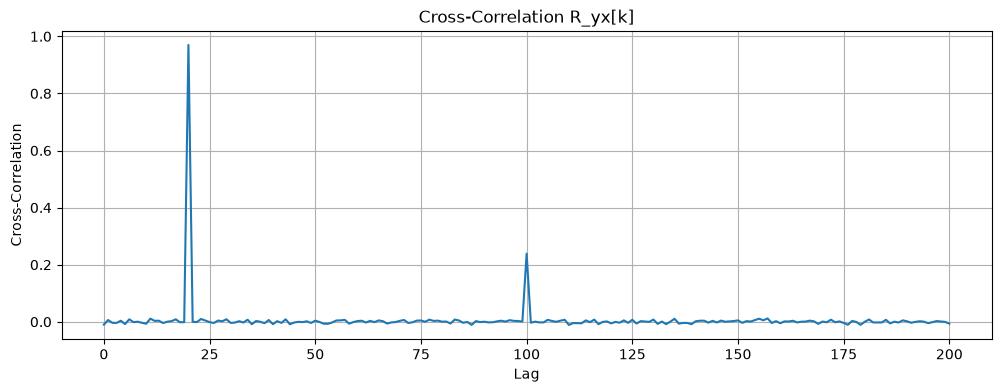

Max |R_yx|^2: 1624465563.7250, P_x * P_y: 1726650040.5119


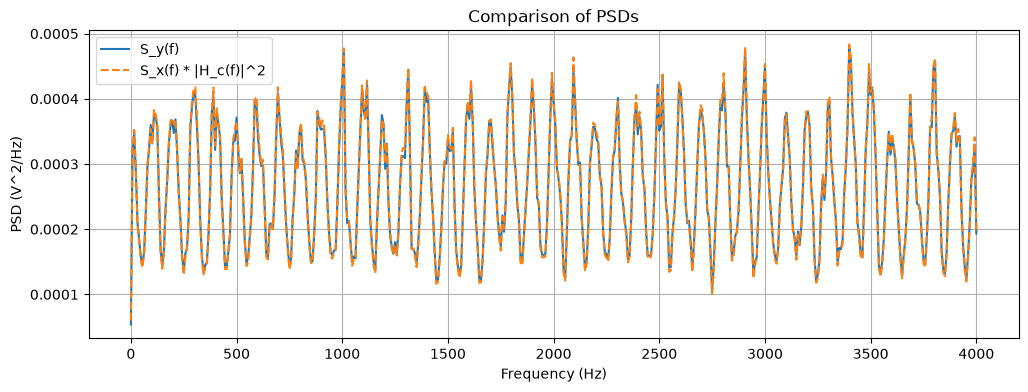

In [32]:
# 4.1 Probe parameters
from re import S

np.random.seed(2026)
N_probe = int(target_sr * 5)
x_probe = np.random.randn(N_probe)

d1_probe = 20
d2_probe = 100
K_echo = 0.25

def two_path_channel(x, delays, gains):
    """
    Applies a Tapped Delay Line (TDL) channel with specified sample delays and tap gains.
    """
    y = np.zeros_like(x, dtype=np.float64)
    for d, g in zip(delays, gains):
        if d == 0:
            y += g * x
        else:
            y[d:] += g * x[:-d]
    return y

y_probe = two_path_channel(x_probe, [d1_probe, d2_probe], [1.0, K_echo])

# TODO: Compute and plot Cross-Correlation R_yx[k] for lags 0 to 200 to identify d1, d2, and K_echo
lags = np.arange(0, 201)
P_x = np.sum(np.abs(x_probe)**2)
P_y = np.sum(np.abs(y_probe)**2)
R_yx = np.correlate(y_probe, x_probe, mode='full')
R_yx = R_yx[len(x_probe)-1:len(x_probe)+200]

plt.figure()
plt.plot(lags, R_yx / (np.sqrt(P_x * P_y)), label='Normalized Cross-Correlation')
plt.xlabel('Lag')
plt.ylabel('Cross-Correlation')
plt.title('Cross-Correlation R_yx[k]')
plt.show()

# TODO: Verify Cauchy-Schwarz inequality max(|R_yx|^2) <= P_x * P_y
R_yx_max_sq = np.max(np.abs(R_yx)**2)

print(f"Max |R_yx|^2: {R_yx_max_sq:.4f}, P_x * P_y: {P_x * P_y:.4f}")
# TODO: Compute Welch PSD S_x(f) and S_y(f) and plot S_y(f) vs S_x(f) * |H_c(f)|^2

f_welch, S_x_f = signal.welch(x_probe, fs=target_sr, nperseg=1024)
_, S_y_f = signal.welch(y_probe, fs=target_sr, nperseg=1024)

# Include both d1_probe and d2_probe in the channel frequency response
H_c_f = (
    np.exp(-1j * 2 * np.pi * f_welch * d1_probe / target_sr)
    + K_echo * np.exp(-1j * 2 * np.pi * f_welch * d2_probe / target_sr)
)

plt.figure()
plt.plot(f_welch, S_y_f, label='S_y(f)')
plt.plot(f_welch, S_x_f * np.abs(H_c_f)**2, '--', label='S_x(f) * |H_c(f)|^2')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (V^2/Hz)')
plt.title('Comparison of PSDs')
plt.legend()
plt.show()

### 4.2. TDL Channel Equalization on the Composite FDM System
Now apply the two-path channel to our high-rate composite 6-user FDM signal `composite_signal` ($f_{\text{sim}} = 500\text{ kHz}$) with:
- Direct delay $d_1 = 0\text{ samples}$ ($t_d = 0$), gain $K_1 = 1.0$
- Echo delay $\Delta d = 250\text{ samples}$ ($\Delta t = 0.5\text{ ms}$), reflection gain $K = 0.20$

1. Pass `composite_signal` through `two_path_channel` to get `composite_tdl_signal` and extract the 6 distorted baseband signals (`baseband_signals_tdl`).
2. Implement `tapped_delay_line_equalizer(input_signals, K, delta_d, num_taps)` based on the truncated geometric series expansion:
   $$H_{\text{eq}}(f) = \frac{1}{1 + K e^{-j2\pi f \Delta t}} \approx \sum_{m=0}^{M-1} (-K)^m e^{-j2\pi f m \Delta t}$$
3. Apply the equalizer for $M \in \{2, 4, 8\}$ taps, compute the MSE across all 6 channels before and after equalization, and save the downsampled `.wav` audio files (`target_sr = 8000` Hz) using `soundfile.write`.

In [33]:
delta_d_fdm = 250   # Echo delay in samples at fs_simulation = 500 kHz
K_fdm = 0.20        # Echo attenuation factor

# 1. Apply TDL channel to composite_signal
composite_tdl_signal = two_path_channel(composite_signal, [0, delta_d_fdm], [1.0, K_fdm])

# 2. Implement Series-Expansion TDL Equalizer
def tapped_delay_line_equalizer(input_signal, K, delta_d, num_taps=5):
    """
    Compensates a two-path channel y[n] = x[n] + K * x[n - delta_d]
    using the series expansion sum_{m=0}^{num_taps-1} (-K)^m * y[n - m * delta_d].
    """
    # TODO: Compute tap delays and tap weights (-K)^m and apply two_path_channel
    equalized = np.zeros_like(input_signal, dtype=np.float64)
    for m in range(num_taps):
        delay = m * delta_d
        weight = (-K) ** m
        if delay == 0:
            equalized += weight * input_signal
        else:
            equalized[delay:] += weight * input_signal[:-delay]
        
    return equalized

# TODO: Equalize the signal for num_taps in [2, 4, 8], extract the 6 baseband channels,
# compute and plot MSE before and after equalization, and save downsampled .wav files.

def extract_baseband_channels(composite_signal, fs, center_freqs, f_if, target_sr, t):
    N_freqs = len(center_freqs) #number of channels
    baseband_signals = np.zeros((N_freqs, audio_vectors.shape[1]))
    for i, cent_freq in enumerate(center_freqs):
        baseband_signal = extract_channel_if(
        composite_signal, fs, cent_freq, f_if, target_sr, t
    )
        baseband_signals[i] = baseband_signal[:audio_vectors.shape[1]]
    return baseband_signals

baseband_signals_tdl = extract_baseband_channels(composite_tdl_signal, fs_simulation, center_freqs, f_if, target_sr, t)
baseband_signals_ref = extract_baseband_channels(composite_signal, fs_simulation, center_freqs, f_if, target_sr, t)


# Compute MSE before equalization across all 6 channels
mse_before = [
    np.mean((ref - dist) ** 2)
    for ref, dist in zip(baseband_signals_ref, baseband_signals_tdl)
]


tap_counts = [2, 4, 8]
mse_after_dict = {}

for M in tap_counts:
    # Equalize at the composite passband rate (500 kHz)
    eq_composite = tapped_delay_line_equalizer(
        composite_tdl_signal, K_fdm, delta_d_fdm, num_taps=M
    )
    
    # Extract the 6 equalized baseband channels (downsampled to 8000 Hz)
    baseband_eq = extract_baseband_channels(eq_composite, fs_simulation, center_freqs, f_if, target_sr, t)
    
    # Compute per-channel MSE after equalization
    mse_after_dict[M] = [
        np.mean((ref - eq) ** 2)
        for ref, eq in zip(baseband_signals_ref, baseband_eq)
    ]
    
    # Save downsampled .wav files for each user
    for ch_idx, sig_8k in enumerate(baseband_eq):
        # Clip to [-1.0, 1.0] to avoid PCM clipping artifacts when writing float audio
        sig_to_write = np.clip(sig_8k, -1.0, 1.0)
        sf.write(f"user_{ch_idx + 1}_eq_M{M}.wav", sig_to_write, target_sr)


print(f"Mean MSE Before Equalization: {np.mean(mse_before):.6e}")
for M in tap_counts:
    print(f"Mean MSE After Equalization (M={M}): {np.mean(mse_after_dict[M]):.6e}")


Mean MSE Before Equalization: 5.497814e-03
Mean MSE After Equalization (M=2): 1.963171e-04
Mean MSE After Equalization (M=4): 1.579722e-07
Mean MSE After Equalization (M=8): 3.852602e-13


**Question 4 Final Analysis:**
- *How does the two-path channel $H_c(f) = 1 + K e^{-j2\pi f \Delta t}$ create periodic ripples (comb filtering) in the Power Spectral Density $S_y(f)$, and what determines the frequency spacing between two consecutive spectral nulls?*
- *Under what condition on $|K|$ does the series-expansion equalizer $\sum_{m=0}^{\infty} (-K)^m e^{-j2\pi f m \Delta t}$ converge (BIBO stability)? Compare the audio quality and MSE across all sections of this assignment.*

**Answer:**


The two-path channel combines a direct path with a delayed echo, causing constructive and destructive interference, with spacing given by $\Delta f = \frac{1}{\Delta t}$.



The series-expansion equalizer converges if and only if the reflection coefficient magnitude is strictly less than one ($K< 1$).
